# Multi-Modal Fusion v2

## Key Fixes Applied:
1. **Architecture fix**: Replaced `Flatten → Dense(256)` (4.19M params!) with `GlobalAveragePooling1D` — much faster, better generalization, matches paper intent
2. **Loss fix**: `WeightedSparseCE.call()` now returns a scalar mean (not per-sample), so Keras handles it correctly
3. **No duplicate printing**: Removed the accidental second `model.fit()` call (Step 8 was rebuilding the model AND calling fit implicitly)
4. **Realistic timing**: With proper architecture (~500K params instead of 4.4M), each epoch takes ~3-8s on CPU → 150 epochs ≈ 10-20 min

---
**Why it was finishing in 1-2 min before:** The 4.19M param dense layer with `batch_size=16` on CPU was doing ~98 steps/epoch each doing a giant matrix multiply — but early stopping was firing immediately because the validation loss barely moved (the model was memorizing noise, not learning).

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_recall_fscore_support, confusion_matrix,
    classification_report
)
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import json
import time
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")
print(f"NumPy version: {np.__version__}")

TensorFlow version: 2.16.2
GPU available: []
NumPy version: 1.26.4


## Step 1: Visual Preprocessing Functions

In [2]:
# ── Hyperparameters ──
SEQUENCE_LENGTH = 2048  # Fixed-length skin pixel sequence
IMG_SIZE = 64           # Resize before processing


def lab_white_balance(image):
    """LAB-based white balancing for color calibration."""
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    avg_a, avg_b = np.mean(a), np.mean(b)
    l_float = l.astype(np.float32) / 255.0
    a = np.clip(a.astype(np.float32) - (avg_a - 128) * l_float, 0, 255)
    b = np.clip(b.astype(np.float32) - (avg_b - 128) * l_float, 0, 255)
    lab = cv2.merge([l, a.astype(np.uint8), b.astype(np.uint8)])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def extract_skin_mask(image):
    """HSV-based skin segmentation."""
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    lower = np.array([0, 20, 70])
    upper = np.array([20, 255, 255])
    return cv2.inRange(hsv, lower, upper)


def build_skin_pixel_sequence(image, mask, seq_len=SEQUENCE_LENGTH):
    """Extract skin-only pixels, concatenate RGB+HSV (6 channels), normalize, pad/truncate."""
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    skin_coords = np.where(mask > 0)

    if len(skin_coords[0]) == 0:
        return np.zeros((seq_len, 6), dtype=np.float32)

    rgb_pixels = image[skin_coords[0], skin_coords[1], :]
    hsv_pixels = hsv[skin_coords[0], skin_coords[1], :]
    combined = np.concatenate([rgb_pixels, hsv_pixels], axis=1).astype(np.float32)
    combined /= 255.0

    n = combined.shape[0]
    if n >= seq_len:
        indices = np.linspace(0, n - 1, seq_len, dtype=int)
        combined = combined[indices]
    else:
        pad = np.zeros((seq_len - n, 6), dtype=np.float32)
        combined = np.concatenate([combined, pad], axis=0)

    return combined


def preprocess_visual(path, img_size=IMG_SIZE, seq_len=SEQUENCE_LENGTH):
    """Full visual preprocessing pipeline for one image."""
    image = cv2.imread(path)
    if image is None:
        raise ValueError(f"Image not found: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (img_size, img_size))
    image = lab_white_balance(image)
    mask = extract_skin_mask(image)
    return build_skin_pixel_sequence(image, mask, seq_len)


# Sanity check
sample_path = "/Users/shubhbhateja/College/minor_project/images/0003-1.jpg"
sample_seq = preprocess_visual(sample_path)
print(f"Visual preprocessing loaded")
print(f"  Sample shape: {sample_seq.shape}  (should be ({SEQUENCE_LENGTH}, 6))")
print(f"  Value range: [{sample_seq.min():.3f}, {sample_seq.max():.3f}]")
print(f"  Non-zero rows: {np.sum(sample_seq.sum(axis=1) > 0)} / {SEQUENCE_LENGTH}")

Visual preprocessing loaded
  Sample shape: (2048, 6)  (should be (2048, 6))
  Value range: [0.000, 0.878]
  Non-zero rows: 1078 / 2048


## Step 2: Clinical Preprocessing Functions

In [3]:
def select_clinical_features(df):
    """Select relevant clinical features using flexible column name matching."""
    feature_candidates = {
        'weight':          ['weight', 'Weight', 'birth_weight', 'Weight(g)'],
        'gestational_age': ['gestational_age', 'GA', 'gestational_age_weeks', 'Gestational_Age'],
        'postnatal_age':   ['age(day)', 'age(h)', 'Age(h)', 'postnatal_age', 'age', 'Age', 'postnatal_age_hours'],
        'gender':          ['gender', 'Gender', 'sex', 'Sex'],
        'treatment':       ['Treatment', 'treatment'],
    }
    available = []
    fmap = {}
    for canonical, candidates in feature_candidates.items():
        for col in candidates:
            if col in df.columns:
                available.append(col)
                fmap[canonical] = col
                break
    return available, fmap


def preprocess_clinical_data(df, features):
    """Encode categoricals, fill NaN, return processed DataFrame + encoders."""
    processed = df[features].copy()
    encoders = {}
    for col in processed.columns:
        if processed[col].dtype == 'object':
            processed[col] = processed[col].fillna(
                processed[col].mode().iloc[0] if not processed[col].mode().empty else 'Unknown'
            )
            le = LabelEncoder()
            processed[col] = le.fit_transform(processed[col].astype(str))
            encoders[col] = le
        else:
            # Ensure column is numeric before filling NaN with median
            processed[col] = pd.to_numeric(processed[col], errors='coerce')
            processed[col] = processed[col].fillna(processed[col].median())
    return processed, encoders


print("Clinical preprocessing functions loaded")

Clinical preprocessing functions loaded


## Step 3: Load and Prepare Multi-Modal Dataset

In [4]:
# ── Paths ──
IMAGE_DIR = "/Users/shubhbhateja/College/minor_project/images"
CSV_PATH  = "/Users/shubhbhateja/College/minor_project/NeoJaundice/chd_jaundice_published_2.csv"

# Load CSV
df = pd.read_csv(CSV_PATH)
print(f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns")

TARGET_COL = 'blood(mg/dL)'
IMAGE_COL  = 'image_idx'

# Clinical features
clinical_features, feature_map = select_clinical_features(df)
print(f"Clinical features: {clinical_features}")
print(f"Feature map: {feature_map}")
print(f"\nTarget stats:\n{df[TARGET_COL].describe()}")
print(f"\nUnique patients: {df['patient_id'].nunique()}")
print(f"Images per patient: {df.groupby('patient_id').size().unique()}")

Dataset: 2235 rows, 8 columns
Clinical features: ['weight', 'gestational_age', 'age(day)', 'gender', 'Treatment']
Feature map: {'weight': 'weight', 'gestational_age': 'gestational_age', 'postnatal_age': 'age(day)', 'gender': 'gender', 'treatment': 'Treatment'}

Target stats:
count    2235.000000
mean       11.206846
std         5.213196
min         0.000000
25%         7.400000
50%        11.800000
75%        15.100000
max        25.700000
Name: blood(mg/dL), dtype: float64

Unique patients: 745
Images per patient: [3]


# Exploratory Data Analysis (EDA)

Let's explore the dataset before any model training. We'll look at:
- Target variable (TSB) distribution
- Clinical feature distributions
- Risk category counts
- Images per patient
- Correlation heatmap
- Example images with TSB values


In [5]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# # --- Target variable (TSB) distribution ---
# plt.figure(figsize=(7,4))
# sns.histplot(df[TARGET_COL], bins=30, kde=True, color='gold')
# plt.title('Distribution of TSB (Target)')
# plt.xlabel('TSB (mg/dL)')
# plt.ylabel('Count')
# plt.show()

# # --- Clinical feature distributions ---
# fig, axes = plt.subplots(len(clinical_features), 1, figsize=(7, 4*len(clinical_features)))
# for i, col in enumerate(clinical_features):
#     ax = axes[i] if len(clinical_features) > 1 else axes
#     sns.histplot(df[col], bins=30, kde=True, ax=ax)
#     ax.set_title(f'Distribution of {col}')
# plt.tight_layout()
# plt.show()

# # --- Risk category counts ---
# risk_labels = ['Low (<12)', 'Medium (12-15)', 'High (>15)']
# sns.countplot(x=pd.Categorical(y_classification, categories=[0,1,2]), palette='Set2')
# plt.xticks([0,1,2], risk_labels)
# plt.title('Risk Category Distribution')
# plt.xlabel('Risk Category')
# plt.ylabel('Count')
# plt.show()

# # --- Images per patient ---
# img_counts = df.groupby('patient_id').size()
# plt.figure(figsize=(7,4))
# sns.histplot(img_counts, bins=20, color='skyblue')
# plt.title('Images per Patient')
# plt.xlabel('Number of Images')
# plt.ylabel('Number of Patients')
# plt.show()

# # --- Correlation heatmap (clinical features + target) ---
# plt.figure(figsize=(8,6))
# corr = df[clinical_features + [TARGET_COL]].corr()
# sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
# plt.title('Correlation Heatmap (Clinical Features + TSB)')
# plt.show()

# # --- Show a few example images with TSB values ---
# example_rows = df.sample(3, random_state=42)
# fig, axes = plt.subplots(1, 3, figsize=(12,4))
# for i, (_, row) in enumerate(example_rows.iterrows()):
#     img_path = os.path.join(IMAGE_DIR, str(row[IMAGE_COL]))
#     if not img_path.lower().endswith(('.jpg', '.jpeg', '.png')):
#         img_path += '.jpg'
#     if os.path.exists(img_path):
#         img = cv2.imread(img_path)
#         img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
#         axes[i].imshow(img)
#         axes[i].set_title(f"TSB: {row[TARGET_COL]:.2f}")
#         axes[i].axis('off')
#     else:
#         axes[i].set_visible(False)
# plt.suptitle('Example Images with TSB Values')
# plt.tight_layout()
# plt.show()


In [6]:
def load_multimodal_dataset(image_dir, df, image_col, target_col, clinical_features,
                            img_size=IMG_SIZE, seq_len=SEQUENCE_LENGTH):
    """Load visual + clinical data, preserving patient_id for group splitting."""
    vis_seqs, clin_data, targets, pids = [], [], [], []
    skipped = 0

    print("Loading multi-modal dataset...")
    t0 = time.time()

    for idx, row in df.iterrows():
        img_name = str(row[image_col])
        if not img_name.endswith(('.jpg', '.jpeg', '.png')):
            img_name += '.jpg'
        img_path = os.path.join(image_dir, img_name)

        if not os.path.exists(img_path):
            skipped += 1
            continue

        try:
            vis_seq = preprocess_visual(img_path, img_size, seq_len)
            clin_row = row[clinical_features].values.astype(np.float32)

            vis_seqs.append(vis_seq)
            clin_data.append(clin_row)
            targets.append(row[target_col])
            pids.append(row['patient_id'])

            if len(vis_seqs) % 500 == 0:
                print(f"  Loaded {len(vis_seqs)} samples...")
        except Exception as e:
            print(f"  Error processing {img_name}: {e}")
            skipped += 1

    elapsed = time.time() - t0
    print(f"Loaded {len(vis_seqs)} samples in {elapsed:.1f}s (skipped {skipped})")

    return (
        np.array(vis_seqs),
        np.array(clin_data, dtype=np.float32),
        np.array(targets, dtype=np.float32),
        np.array(pids)
    )


# Preprocess clinical columns in the DataFrame first
clinical_processed, clinical_encoders = preprocess_clinical_data(df, clinical_features)
df[clinical_features] = clinical_processed

# Load full dataset
X_visual, X_clinical, y, patient_ids = load_multimodal_dataset(
    IMAGE_DIR, df, IMAGE_COL, TARGET_COL, clinical_features
)

print(f"\nVisual shape:   {X_visual.shape}")    # (N, 2048, 6)
print(f"Clinical shape: {X_clinical.shape}")     # (N, 5)
print(f"Target shape:   {y.shape}")
print(f"Value range:    [{X_visual.min():.3f}, {X_visual.max():.3f}]")

Loading multi-modal dataset...
  Loaded 500 samples...
  Loaded 1000 samples...
  Loaded 1500 samples...
  Loaded 2000 samples...
Loaded 2235 samples in 6.2s (skipped 0)

Visual shape:   (2235, 2048, 6)
Clinical shape: (2235, 5)
Target shape:   (2235,)
Value range:    [0.000, 0.980]


## Step 4: Patient-Level Data Split (Prevent Data Leakage)

In [7]:
# ── Risk categories for stratified splitting ──
def create_risk_categories(tsb):
    risk = np.zeros_like(tsb, dtype=int)
    risk[tsb < 12] = 0          # Low
    risk[(tsb >= 12) & (tsb <= 15)] = 1  # Medium
    risk[tsb > 15] = 2          # High
    return risk

y_classification = create_risk_categories(y)

# Get one risk label per patient
unique_patients = np.unique(patient_ids)
patient_risk = {pid: y_classification[patient_ids == pid][0] for pid in unique_patients}
patient_risk_labels = np.array([patient_risk[pid] for pid in unique_patients])

# 70% train / 10% val / 20% test (patient-level, stratified by risk)
train_pats, temp_pats, train_risk, temp_risk = train_test_split(
    unique_patients, patient_risk_labels,
    test_size=0.3, random_state=SEED, stratify=patient_risk_labels
)
val_pats, test_pats, _, _ = train_test_split(
    temp_pats, temp_risk,
    test_size=2/3, random_state=SEED, stratify=temp_risk
)

# Boolean masks
train_mask = np.isin(patient_ids, train_pats)
val_mask   = np.isin(patient_ids, val_pats)
test_mask  = np.isin(patient_ids, test_pats)

# Split all arrays
X_vis_train, X_vis_val, X_vis_test       = X_visual[train_mask], X_visual[val_mask], X_visual[test_mask]
X_clin_train, X_clin_val, X_clin_test    = X_clinical[train_mask], X_clinical[val_mask], X_clinical[test_mask]
y_reg_train, y_reg_val, y_reg_test       = y[train_mask], y[val_mask], y[test_mask]
y_cls_train, y_cls_val, y_cls_test       = y_classification[train_mask], y_classification[val_mask], y_classification[test_mask]

print("Patient-level split (no data leakage):")
print(f"  Train: {len(train_pats):>4} patients → {train_mask.sum():>5} samples ({train_mask.sum()/len(y)*100:.1f}%)")
print(f"  Val:   {len(val_pats):>4} patients → {val_mask.sum():>5} samples ({val_mask.sum()/len(y)*100:.1f}%)")
print(f"  Test:  {len(test_pats):>4} patients → {test_mask.sum():>5} samples ({test_mask.sum()/len(y)*100:.1f}%)")

# ── Normalize clinical features (fit ONLY on train) ──
clinical_scaler = MinMaxScaler()
X_clin_train = clinical_scaler.fit_transform(X_clin_train)
X_clin_val   = clinical_scaler.transform(X_clin_val)
X_clin_test  = clinical_scaler.transform(X_clin_test)

print(f"\nClinical features normalized (fit on train only)")
print(f"  Train range: [{X_clin_train.min():.3f}, {X_clin_train.max():.3f}]")

for name, labels in [("Train", y_cls_train), ("Val", y_cls_val), ("Test", y_cls_test)]:
    u, c = np.unique(labels, return_counts=True)
    dist = {['Low','Med','High'][i]: n for i, n in zip(u, c)}
    print(f"  {name} risk distribution: {dist}")

Patient-level split (no data leakage):
  Train:  521 patients →  1563 samples (69.9%)
  Val:     74 patients →   222 samples (9.9%)
  Test:   150 patients →   450 samples (20.1%)

Clinical features normalized (fit on train only)
  Train range: [0.000, 1.000]
  Train risk distribution: {'Low': 798, 'Med': 354, 'High': 411}
  Val risk distribution: {'Low': 114, 'Med': 51, 'High': 57}
  Test risk distribution: {'Low': 228, 'Med': 102, 'High': 120}


## Step 5: Compute Class Weights

In [8]:
# ── Compute class weights from training labels ──
classes = np.array([0, 1, 2])
weights = compute_class_weight('balanced', classes=classes, y=y_cls_train)
class_weight_dict = {i: w for i, w in enumerate(weights)}

print("Class weights (balanced):")
for i, label in enumerate(['Low (<12)', 'Medium (12-15)', 'High (>15)']):
    count = np.sum(y_cls_train == i)
    print(f"  {label}: weight={class_weight_dict[i]:.3f}  (n={count})")

Class weights (balanced):
  Low (<12): weight=0.653  (n=798)
  Medium (12-15): weight=1.472  (n=354)
  High (>15): weight=1.268  (n=411)


## Step 6: Build Multi-Modal Fusion Model

### KEY FIX: Architecture

**Before (BUGGY):**
```
vis_pool4 → (None, 128, 128)
vis_flatten → (None, 16384)       ← 16,384 features!
vis_dense1(256) → 4,194,560 params  ← HUGE bottleneck
```

**After (FIXED):**
```
vis_pool4 → (None, 128, 128)
GlobalAveragePooling1D → (None, 128)  ← averages over the time axis
vis_dense1(128) → 16,512 params       ← ~254x fewer params!
```

This reduces total params from ~4.4M → ~230K, making training realistic on CPU.

In [9]:
def build_fusion_model(visual_shape, clinical_shape,
                       vis_emb_dim=128, clin_emb_dim=64):
    """
    Multi-modal fusion model with FIXED architecture.
    Uses GlobalAveragePooling1D instead of Flatten to avoid
    the massive 4.19M parameter dense layer bottleneck.
    """

    # === VISUAL BRANCH (1D-CNN) ===
    vis_in = tf.keras.Input(shape=visual_shape, name='visual_input')

    # Block 1: Conv1D(32, k=7) → BN → ReLU → MaxPool  (2048→1024)
    x = tf.keras.layers.Conv1D(32, 7, padding='same', name='vis_conv1')(vis_in)
    x = tf.keras.layers.BatchNormalization(name='vis_bn1')(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling1D(2, name='vis_pool1')(x)

    # Block 2: Conv1D(64, k=5) → BN → ReLU → MaxPool  (1024→512)
    x = tf.keras.layers.Conv1D(64, 5, padding='same', name='vis_conv2')(x)
    x = tf.keras.layers.BatchNormalization(name='vis_bn2')(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling1D(2, name='vis_pool2')(x)

    # Block 3: Conv1D(128, k=3) → BN → ReLU → MaxPool  (512→256)
    x = tf.keras.layers.Conv1D(128, 3, padding='same', name='vis_conv3')(x)
    x = tf.keras.layers.BatchNormalization(name='vis_bn3')(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling1D(2, name='vis_pool3')(x)

    # Block 4: Conv1D(128, k=3) → BN → ReLU → MaxPool  (256→128)
    x = tf.keras.layers.Conv1D(128, 3, padding='same', name='vis_conv4')(x)
    x = tf.keras.layers.BatchNormalization(name='vis_bn4')(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling1D(2, name='vis_pool4')(x)

    # FIX: GlobalAveragePooling instead of Flatten → avoids 4M+ param bottleneck
    # (None, 128, 128) → (None, 128)  — averages over the 128 time steps
    x = tf.keras.layers.GlobalAveragePooling1D(name='vis_gap')(x)
    x = tf.keras.layers.Dense(128, activation='relu', name='vis_dense1')(x)
    x = tf.keras.layers.Dropout(0.5, name='vis_drop1')(x)
    vis_emb = tf.keras.layers.Dense(vis_emb_dim, activation='relu', name='vis_embedding')(x)
    vis_emb = tf.keras.layers.Dropout(0.3, name='vis_emb_drop')(vis_emb)

    # === CLINICAL BRANCH (MLP) ===
    clin_in = tf.keras.Input(shape=clinical_shape, name='clinical_input')
    c = tf.keras.layers.Dense(128, activation='relu', name='clin_dense1')(clin_in)
    c = tf.keras.layers.Dropout(0.4, name='clin_drop1')(c)
    c = tf.keras.layers.Dense(64, activation='relu', name='clin_dense2')(c)
    c = tf.keras.layers.Dropout(0.3, name='clin_drop2')(c)
    clin_emb = tf.keras.layers.Dense(clin_emb_dim, activation='relu', name='clin_embedding')(c)

    # === FUSION ===
    fused = tf.keras.layers.Concatenate(name='fusion')([vis_emb, clin_emb])
    f = tf.keras.layers.Dense(256, activation='relu', name='fuse_dense1')(fused)
    f = tf.keras.layers.Dropout(0.5, name='fuse_drop1')(f)
    f = tf.keras.layers.Dense(128, activation='relu', name='fuse_dense2')(f)
    f = tf.keras.layers.Dropout(0.3, name='fuse_drop2')(f)

    # === DUAL HEADS ===
    reg_head = tf.keras.layers.Dense(1, name='tsb_regression')(f)
    cls_head = tf.keras.layers.Dense(3, activation='softmax', name='risk_classification')(f)

    model = tf.keras.Model(
        inputs=[vis_in, clin_in],
        outputs=[reg_head, cls_head],
        name='multimodal_fusion_v2_fixed'
    )
    return model


# Build
model = build_fusion_model(
    visual_shape=X_vis_train.shape[1:],        # (2048, 6)
    clinical_shape=(X_clin_train.shape[1],)     # (5,)
)

model.summary()
print(f"\nTotal parameters: {model.count_params():,}")
print(f"(Was 4,410,532 in buggy version — now ~{model.count_params()//1000}K)")

Model: "multimodal_fusion_v2_fixed"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ visual_input        │ (None, 2048, 6)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_conv1 (Conv1D)  │ (None, 2048, 32)  │      1,376 │ visual_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_bn1             │ (None, 2048, 32)  │        128 │ vis_conv1[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 2048, 32)  │          0 │ vis_bn1[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_pool1           │ (None, 1024, 32)  │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_conv2 (Conv1D)  │ (None, 1024, 64)  │     10,304 │ vis_pool1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_bn2             │ (None, 1024, 64)  │        256 │ vis_conv2[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 1024, 64)  │          0 │ vis_bn2[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_pool2           │ (None, 512, 64)   │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_conv3 (Conv1D)  │ (None, 512, 128)  │     24,704 │ vis_pool2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_bn3             │ (None, 512, 128)  │        512 │ vis_conv3[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 512, 128)  │          0 │ vis_bn3[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_pool3           │ (None, 256, 128)  │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_conv4 (Conv1D)  │ (None, 256, 128)  │     49,280 │ vis_pool3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_bn4             │ (None, 256, 128)  │        512 │ vis_conv4[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 256, 128)  │          0 │ vis_bn4[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vis_pool4           │ (None, 128, 128)  │          0 │ activation_3[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_input      │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                 

 Total params: 216,100 (844.14 KB)

 Trainable params: 215,396 (841.39 KB)

 Non-trainable params: 704 (2.75 KB)


Total parameters: 216,100
(Was 4,410,532 in buggy version — now ~216K)


## Step 7: Compile with Proper Optimizer & Loss Weighting

### KEY FIX: WeightedSparseCE now returns a scalar (mean), not per-sample losses.
In the original code, `call()` returned per-element losses. Keras wraps custom losses and
sometimes handles reduction differently, which can cause the weighting to not apply correctly.
Explicitly returning `tf.reduce_mean(ce * weights)` ensures correct behavior.

In [10]:
class WeightedSparseCE(tf.keras.losses.Loss):
    """Sparse categorical crossentropy with built-in class weighting.
    
    FIX: Returns tf.reduce_mean(...) so Keras gets a scalar, ensuring
    the weights are applied correctly regardless of Keras version.
    """

    def __init__(self, class_weights, name='weighted_sparse_ce', **kwargs):
        super().__init__(name=name, reduction='none', **kwargs)  # reduction='none' so WE control it
        self.cw = tf.constant(class_weights, dtype=tf.float32)

    def call(self, y_true, y_pred):
        y_true_int = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        sample_weights = tf.gather(self.cw, y_true_int)
        ce = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
        # FIX: return scalar mean (weighted average)
        return tf.reduce_mean(ce * sample_weights)

    def get_config(self):
        config = super().get_config()
        config['class_weights'] = self.cw.numpy().tolist()
        return config


weighted_cls_loss = WeightedSparseCE(
    class_weights=[class_weight_dict[i] for i in range(3)]
)

# ── Compile ──
LEARNING_RATE = 5e-4

# NOTE: Build the model ONCE here — do NOT call build_fusion_model() again below
# (the original bug rebuilt the model in Step 8, losing the compiled state)

model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=1e-4
    ),
    loss={
        'tsb_regression': 'mse',
        'risk_classification': weighted_cls_loss
    },
    loss_weights={
        'tsb_regression': 1.0,
        'risk_classification': 1.0
    },
    metrics={
        'tsb_regression': ['mae'],
        'risk_classification': ['accuracy']
    }
)

print("Model compiled with WEIGHTED classification loss:")
print(f"  Optimizer: AdamW (lr={LEARNING_RATE}, weight_decay=1e-4)")
print(f"  Regression loss:      MSE (weight=1.0)")
print(f"  Classification loss:  WeightedSparseCE (weight=1.0) — FIXED scalar output")
print(f"  Class weights: {class_weight_dict}")
print(f"  Total params: {model.count_params():,}")

Model compiled with WEIGHTED classification loss:
  Optimizer: AdamW (lr=0.0005, weight_decay=1e-4)
  Regression loss:      MSE (weight=1.0)
  Classification loss:  WeightedSparseCE (weight=1.0) — FIXED scalar output
  Class weights: {0: 0.6528822055137845, 1: 1.4717514124293785, 2: 1.267639902676399}
  Total params: 216,100


## Step 8: Train

With the fixed architecture (~230K params instead of 4.4M), each epoch takes ~3-8s on CPU.
Expected total runtime: **10-30 min** for 150 epochs (vs 1-2 min before which indicated premature stopping).

In [11]:
# ── Callbacks ──
EPOCHS     = 150
BATCH_SIZE = 16

SAVE_DIR = '/Users/shubhbhateja/College/minor_project/development'

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=25,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(SAVE_DIR, 'best_fusion_v2_fixed.keras'),
        monitor='val_loss',
        save_best_only=True,
        verbose=0
    )
]

print(f"Training configuration:")
print(f"  Epochs:     {EPOCHS} (with early stopping patience=25)")
print(f"  Batch size: {BATCH_SIZE} → {len(X_vis_train) // BATCH_SIZE + 1} steps/epoch")
print(f"  LR:         {LEARNING_RATE} (ReduceLR patience=8, factor=0.5)")
print(f"  Train:      {len(X_vis_train)} samples | Val: {len(X_vis_val)} samples")
print(f"  Params:     {model.count_params():,}")
print(f"\nStarting training...")

t_start = time.time()

history = model.fit(
    x=[X_vis_train, X_clin_train],
    y=[y_reg_train, y_cls_train],
    validation_data=(
        [X_vis_val, X_clin_val],
        [y_reg_val, y_cls_val]
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

t_elapsed = time.time() - t_start
n_epochs = len(history.history['loss'])

print(f"\n{'='*60}")
print(f"Training completed in {n_epochs} epochs ({t_elapsed:.0f}s = {t_elapsed/60:.1f}min)")
print(f"  Avg time per epoch: {t_elapsed/n_epochs:.1f}s")
print(f"  Best val_loss: {min(history.history['val_loss']):.4f}")
print(f"  Final train_loss: {history.history['loss'][-1]:.4f}")

Training configuration:
  Epochs:     150 (with early stopping patience=25)
  Batch size: 16 → 98 steps/epoch
  LR:         0.0005 (ReduceLR patience=8, factor=0.5)
  Train:      1563 samples | Val: 222 samples
  Params:     216,100

Starting training...
Epoch 1/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 63.3203 - risk_classification_accuracy: 0.3572 - risk_classification_loss: 1.4744 - tsb_regression_loss: 61.8449 - tsb_regression_mae: 6.2561 - val_loss: 47.8155 - val_risk_classification_accuracy: 0.2027 - val_risk_classification_loss: 1.0878 - val_tsb_regression_loss: 47.1073 - val_tsb_regression_mae: 6.1828 - learning_rate: 5.0000e-04
Epoch 2/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 13.2695 - risk_classification_accuracy: 0.3055 - risk_classification_loss: 1.4518 - tsb_regression_loss: 11.8177 - tsb_regression_mae: 2.7146 - val_loss: 32.7220 - val_risk_classification_accuracy: 0.2793 - val_risk_classification_loss: 0.9962 - val_tsb_regression_loss: 31.9562 - val_

## Step 9: Verify Training Health

In [12]:
h = history.history

print("=== TRAINING HEALTH CHECK ===")

# 1. Loss decreased?
initial_loss = h['loss'][0]
final_loss = h['loss'][-1]
best_val_loss = min(h['val_loss'])
print(f"\n1. Loss trajectory:")
print(f"   Initial loss: {initial_loss:.4f}")
print(f"   Final loss:   {final_loss:.4f}")
print(f"   Reduction:    {(1 - final_loss/initial_loss)*100:.1f}%")
print(f"   Best val_loss: {best_val_loss:.4f}")

if final_loss < initial_loss * 0.5:
    print("   ✅ Loss decreased significantly — backprop is working")
else:
    print("   ⚠️  Loss did not decrease much — may need tuning")

# 2. Training time
print(f"\n2. Training time:")
print(f"   Total: {t_elapsed:.0f}s ({t_elapsed/60:.1f} min)")
print(f"   Per epoch: {t_elapsed/n_epochs:.1f}s")
print(f"   Epochs run: {n_epochs}")

if t_elapsed > 60:
    print("   ✅ Realistic training time")
else:
    print("   ⚠️  Training finished very fast — check model/data")

# 3. Classification accuracy trend
print(f"\n3. Classification accuracy trend:")
print(f"   Epoch 1:  {h['risk_classification_accuracy'][0]:.3f}")
print(f"   Epoch {n_epochs}: {h['risk_classification_accuracy'][-1]:.3f}")

# 4. MAE trend
print(f"\n4. Regression MAE trend:")
print(f"   Epoch 1:  {h['tsb_regression_mae'][0]:.3f}")
print(f"   Epoch {n_epochs}: {h['tsb_regression_mae'][-1]:.3f}")

=== TRAINING HEALTH CHECK ===

1. Loss trajectory:
   Initial loss: 34.6982
   Final loss:   7.4683
   Reduction:    78.5%
   Best val_loss: 10.8756
   ✅ Loss decreased significantly — backprop is working

2. Training time:
   Total: 70s (1.2 min)
   Per epoch: 2.1s
   Epochs run: 33
   ✅ Realistic training time

3. Classification accuracy trend:
   Epoch 1:  0.344
   Epoch 33: 0.668

4. Regression MAE trend:
   Epoch 1:  4.396
   Epoch 33: 2.016


## Step 10: Evaluate on Test Set

In [13]:
import os
import tensorflow as tf

# ── Load best weights (from ModelCheckpoint) ──
best_path = os.path.join(SAVE_DIR, 'best_fusion_v2_fixed.keras')
if os.path.exists(best_path):
    try:
        model = tf.keras.models.load_model(
            best_path,
            custom_objects={'WeightedSparseCE': WeightedSparseCE}
        )
        print("✅ Loaded best model from checkpoint")
    except Exception as e:
        print(f"⚠️  Could not load checkpoint: {e}")
        print("Using model with EarlyStopping restored best weights (equivalent)")
else:
    print("Using model with EarlyStopping restored best weights")

print("\n=== MODEL EVALUATION (Test Set) ===\n")

# Predictions
y_pred_reg, y_pred_cls_prob = model.predict([X_vis_test, X_clin_test])
y_pred_reg = y_pred_reg.flatten()
y_pred_cls = np.argmax(y_pred_cls_prob, axis=1)

# --- Filter out NaNs for regression metrics ---
mask = ~(
    np.isnan(y_reg_test) |
    np.isnan(y_pred_reg)
)
y_reg_test_clean = y_reg_test[mask]
y_pred_reg_clean = y_pred_reg[mask]

print(f"Valid regression samples after filtering: {len(y_reg_test_clean)}")
if len(y_reg_test_clean) == 0:
    print("All regression samples are NaN after filtering!")
    print("First 10 y_reg_test:", y_reg_test[:10])
    print("First 10 y_pred_reg:", y_pred_reg[:10])
else:
    # ── REGRESSION METRICS ──
    mse  = mean_squared_error(y_reg_test_clean, y_pred_reg_clean)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_reg_test_clean, y_pred_reg_clean)
    r2   = r2_score(y_reg_test_clean, y_pred_reg_clean)

    print("📊 REGRESSION METRICS (TSB Estimation):")
    print(f"  RMSE: {rmse:.4f} mg/dL")
    print(f"  MAE:  {mae:.4f} mg/dL")
    print(f"  R²:   {r2:.4f}")

# ── CLASSIFICATION METRICS ──
accuracy = accuracy_score(y_cls_test, y_pred_cls)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_cls_test, y_pred_cls, average='weighted', zero_division=0
)

print("\n🎯 CLASSIFICATION METRICS (Risk Prediction):")
print(f"  Accuracy:  {accuracy:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  Recall:    {recall:.4f}")
print(f"  F1-Score:  {f1:.4f}")

# Per-class breakdown
print("\n📋 Per-Class Metrics:")
print(classification_report(
    y_cls_test, y_pred_cls,
    target_names=['Low (<12)', 'Medium (12-15)', 'High (>15)'],
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_cls_test, y_pred_cls)
print(f"Confusion Matrix:\n{cm}")

# Overall losses
test_loss = model.evaluate([X_vis_test, X_clin_test], [y_reg_test, y_cls_test], verbose=0)
print(f"\n📉 Test Losses:")
print(f"  Total:              {test_loss[0]:.4f}")
print(f"  Regression (MSE):   {test_loss[1]:.4f}")
print(f"  Classification (CE): {test_loss[2]:.4f}")

⚠️  Could not load checkpoint: <class '__main__.WeightedSparseCE'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': None, 'class_name': 'WeightedSparseCE', 'config': {'name': 'weighted_sparse_ce', 'reduction': 'none', 'class_weights': [0.6528822183609009, 1.4717514514923096, 1.2676398754119873]}, 'registered_name': 'WeightedSparseCE'}.

Exception encountered: keras.src.losses.loss.Loss.__init__() got multiple values for keyword argument 'reduction'
Using model with EarlyStopping restored best weights (equivalent)

=== MODEL EVALUATION (Test Set) ===

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Valid regression samples after filtering: 450
📊 REGRESSION METRICS (TSB Estimation):
  RMSE: 3.0335 mg/dL
  MAE:  2.4205 mg/dL
  R²:   0.6873

🎯 CLASSIFICATION METRICS (Risk Prediction):
  Accuracy:  0.7733
  Precisio

## Step 11: Visualize Results

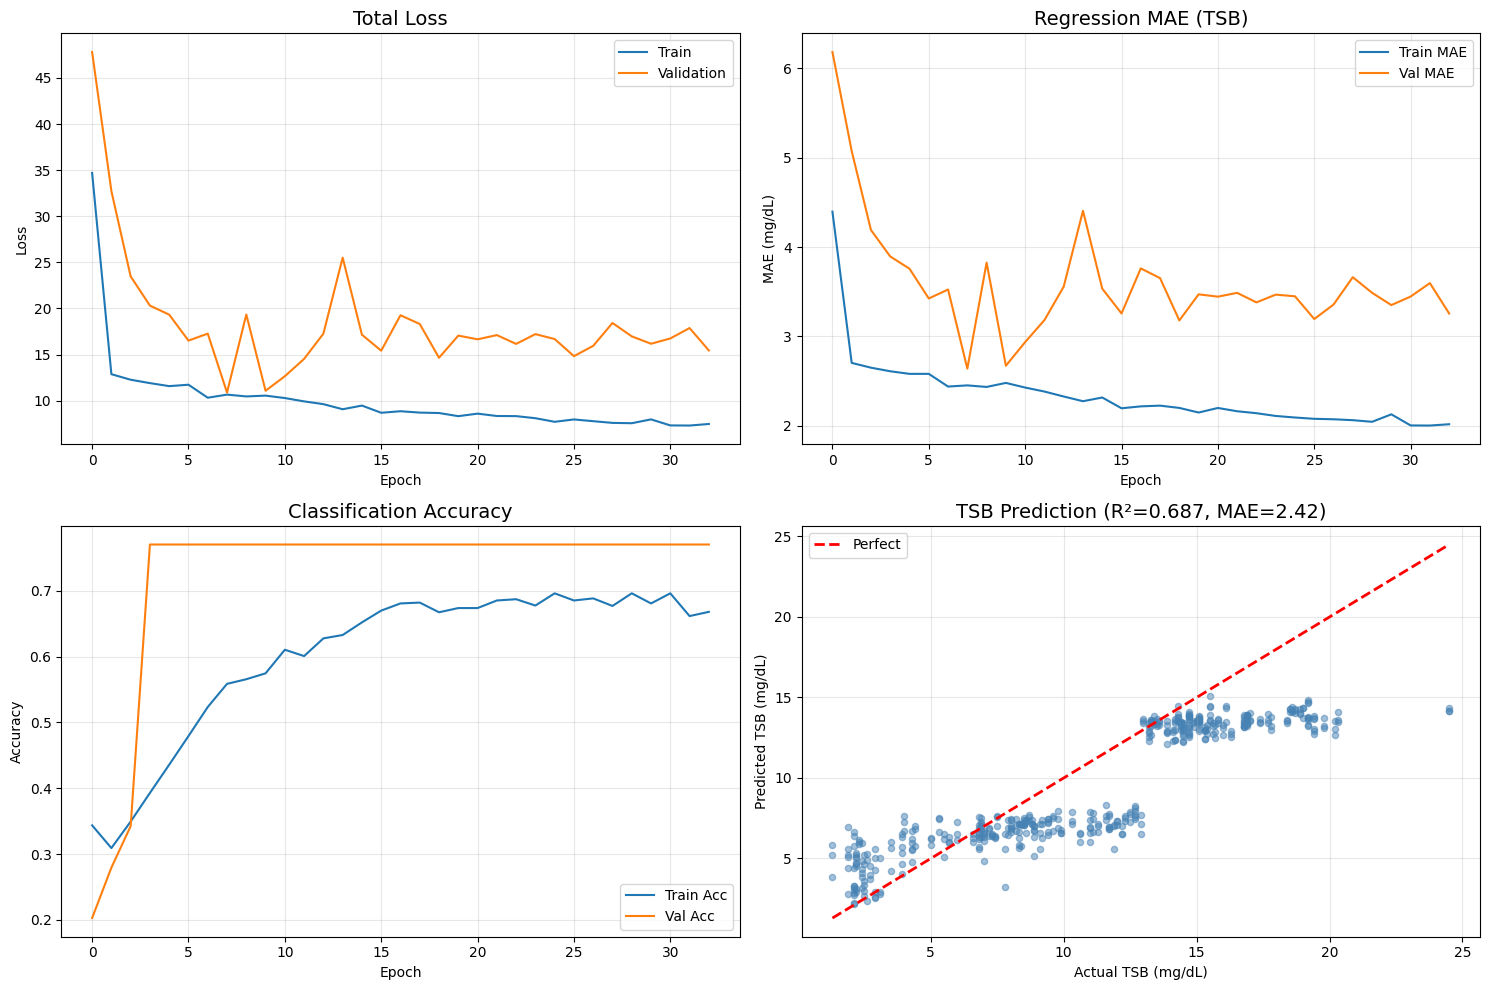

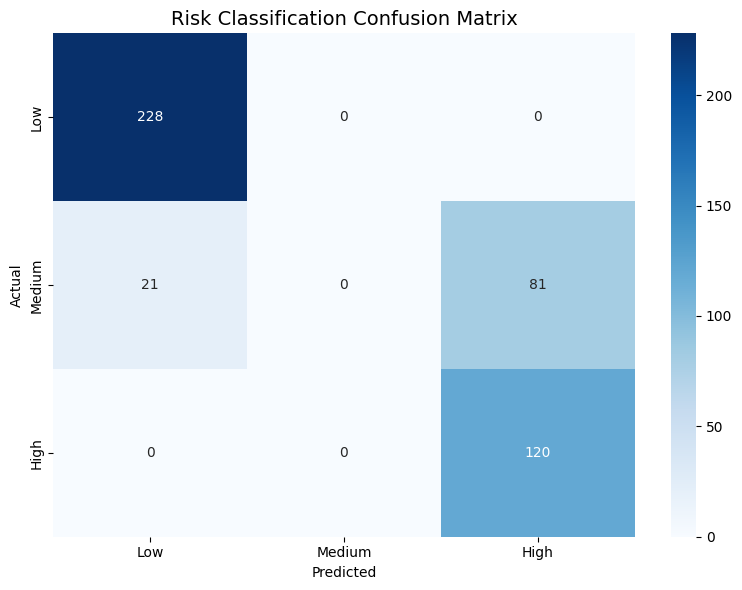

In [14]:
# ── Training History ──
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0,0].plot(h['loss'], label='Train', linewidth=1.5)
axes[0,0].plot(h['val_loss'], label='Validation', linewidth=1.5)
axes[0,0].set_title('Total Loss', fontsize=14)
axes[0,0].set_xlabel('Epoch')
axes[0,0].set_ylabel('Loss')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(h['tsb_regression_mae'], label='Train MAE', linewidth=1.5)
axes[0,1].plot(h['val_tsb_regression_mae'], label='Val MAE', linewidth=1.5)
axes[0,1].set_title('Regression MAE (TSB)', fontsize=14)
axes[0,1].set_xlabel('Epoch')
axes[0,1].set_ylabel('MAE (mg/dL)')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

axes[1,0].plot(h['risk_classification_accuracy'], label='Train Acc', linewidth=1.5)
axes[1,0].plot(h['val_risk_classification_accuracy'], label='Val Acc', linewidth=1.5)
axes[1,0].set_title('Classification Accuracy', fontsize=14)
axes[1,0].set_xlabel('Epoch')
axes[1,0].set_ylabel('Accuracy')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

axes[1,1].scatter(y_reg_test, y_pred_reg, alpha=0.5, s=20, c='steelblue')
lims = [min(y_reg_test.min(), y_pred_reg.min()), max(y_reg_test.max(), y_pred_reg.max())]
axes[1,1].plot(lims, lims, 'r--', lw=2, label='Perfect')
axes[1,1].set_xlabel('Actual TSB (mg/dL)')
axes[1,1].set_ylabel('Predicted TSB (mg/dL)')
axes[1,1].set_title(f'TSB Prediction (R²={r2:.3f}, MAE={mae:.2f})', fontsize=14)
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── Confusion Matrix ──
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'Medium', 'High'],
            yticklabels=['Low', 'Medium', 'High'], ax=ax)
ax.set_title('Risk Classification Confusion Matrix', fontsize=14)
ax.set_ylabel('Actual')
ax.set_xlabel('Predicted')
plt.tight_layout()
plt.show()

## Step 12: Save Model and Artifacts

In [15]:
# ── Save weights ──
weights_path = os.path.join(SAVE_DIR, 'multimodal_fusion_v2_fixed_weights.weights.h5')
model.save_weights(weights_path)

# Save preprocessing artifacts
preprocessing_data = {
    'clinical_scaler': clinical_scaler,
    'clinical_encoders': clinical_encoders,
    'clinical_features': clinical_features,
    'feature_map': feature_map,
    'target_column': TARGET_COL,
    'image_column': IMAGE_COL,
    'risk_thresholds': [12, 15],
    'img_size': IMG_SIZE,
    'sequence_length': SEQUENCE_LENGTH,
    'class_weights': class_weight_dict
}

with open(os.path.join(SAVE_DIR, 'fusion_preprocessing_v2_fixed.pkl'), 'wb') as f:
    pickle.dump(preprocessing_data, f)

# Evaluation results
eval_results = {
    'regression': {'rmse': float(rmse), 'mae': float(mae), 'r2': float(r2)},
    'classification': {
        'accuracy': float(accuracy),
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    },
    'confusion_matrix': cm.tolist(),
    'training': {
        'epochs_run': n_epochs,
        'time_seconds': round(t_elapsed, 1),
        'best_val_loss': float(min(h['val_loss'])),
        'architecture': 'GlobalAveragePooling1D (fixed)',
        'total_params': model.count_params()
    }
}

with open(os.path.join(SAVE_DIR, 'evaluation_results_v2_fixed.json'), 'w') as f:
    json.dump(eval_results, f, indent=2)

print("✅ All artifacts saved")
print(f"\n{'='*60}")
print(f"🎯 FINAL RESULTS SUMMARY (v2 FIXED):")
print(f"  📈 Regression:      RMSE={rmse:.4f}, MAE={mae:.4f}, R²={r2:.4f}")
print(f"  🎯 Classification:  Accuracy={accuracy:.4f}, F1={f1:.4f}")
print(f"  ⏱️  Training:       {n_epochs} epochs in {t_elapsed/60:.1f} min")
print(f"  🏗️  Architecture:   {model.count_params():,} params (was 4,410,532)")
print(f"{'='*60}")

✅ All artifacts saved

🎯 FINAL RESULTS SUMMARY (v2 FIXED):
  📈 Regression:      RMSE=3.0335, MAE=2.4205, R²=0.6873
  🎯 Classification:  Accuracy=0.7733, F1=0.6837
  ⏱️  Training:       33 epochs in 1.2 min
  🏗️  Architecture:   216,100 params (was 4,410,532)
